# Wing Structure 32D Dataset — Full Analysis Pipeline
### Dimensionality Reduction & Clustering

**Dataset:** `wing_structure_32d.csv` — 10,001 samples, 32 features  

---


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Optional: UMAP (install with: pip install umap-learn)
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print("UMAP not installed. Run: pip install umap-learn")

# ── Plot style ──────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor':  '#0e1117',
    'axes.facecolor':    '#161b22',
    'axes.edgecolor':    '#30363d',
    'axes.labelcolor':   '#c9d1d9',
    'axes.titlecolor':   '#e6edf3',
    'xtick.color':       '#8b949e',
    'ytick.color':       '#8b949e',
    'text.color':        '#c9d1d9',
    'grid.color':        '#21262d',
    'grid.linewidth':    0.6,
    'grid.alpha':        1.0,
    'axes.grid':         True,
    'legend.facecolor':  '#161b22',
    'legend.edgecolor':  '#30363d',
    'figure.dpi':        120,
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

PALETTE = ['#00e5c0', '#ff5f57', '#7c6fff', '#ffb830', '#3b82f6', '#22c55e', '#ec4899', '#f97316']
print("Imports complete.")
print(f"UMAP available: {UMAP_AVAILABLE}")


Imports complete.
UMAP available: True


In [3]:
# ── Load ──────────────────────────────────────────────────────
CSV_PATH = Path(__file__).parent / "../data/wing_structure_32d.csv" if "__file__" in dir() else Path("../data/wing_structure_32d.csv")
df = pd.read_csv(CSV_PATH)

print(f"Shape:       {df.shape}")
print(f"Null values: {df.isnull().sum().sum()}")
print(f"Dtypes:      {df.dtypes.value_counts().to_dict()}")
df.head(3)


Shape:       (10001, 32)
Null values: 0
Dtypes:      {dtype('float64'): 31, dtype('int64'): 1}


In [4]:
# ── Descriptive statistics ────────────────────────────────────
df.describe().round(4)


,rootChord,tipChord,semiSpan,wingboxHeight,spanwiseLocRib1,spanwiseLocRib2,spanwiseLocRib3,spanwiseLocRib4,spanwiseLocInboardJacksStart,spanwiseLocInboardJacksEnd,...,spanwiseLocInboardClampEnd,spanwiseLocOutboardClampStart,spanwiseLocOutboardClampEnd,spanwiseLocBottomStrainGage,chordwiseLocBottomStrainGage,spanwiseLocTopStrainGage,chordwiseLocTopStrainGage,tipDisplacement,bottomStrain,topStrain
count,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,...,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000
mean,999.9998,499.9999,4999.9999,100.0000,800.0000,1599.9999,2399.9999,3500.0000,3399.9999,3600.0000,...,200.0000,700.0000,899.9999,2000.0000,-0.0001,2000.0000,-0.0000,62.3073,283.1432,-283.1948
std,0.5774,0.2887,0.5774,0.1155,0.2887,0.5774,0.5774,0.5774,0.5774,0.5774,...,0.0577,0.1155,0.1155,0.1155,0.1155,0.1155,0.1155,1.6539,8.2868,8.2749
min,999.0000,499.5000,4999.0000,99.8000,799.5000,1599.0000,2399.0000,3499.0000,3399.0000,3599.0000,...,199.9000,699.8000,899.8000,1999.8000,-0.2000,1999.8000,-0.2000,57.0721,257.4482,-310.6995
25%,999.4998,499.7500,4999.4998,99.9000,799.7500,1599.5000,2399.5000,3499.4999,3399.5000,3599.5000,...,199.9500,699.9000,899.9000,1999.9000,-0.1000,1999.9000,-0.1000,61.1586,277.4332,-288.9214
50%,999.9998,499.9999,4999.9998,100.0000,800.0000,1600.0000,2399.9999,3499.9999,3399.9999,3599.9998,...,200.0000,700.0000,900.0000,2000.0000,-0.0000,2000.0000,-0.0000,62.3012,283.0474,-283.0689
75%,1000.4998,500.2499,5000.4998,100.1000,800.2500,1600.5000,2400.4999,3500.4999,3400.4999,3600.4998,...,200.0500,700.1000,900.1000,2000.1000,0.1000,2000.1000,0.1000,63.4492,288.8518,-277.5044
max,1000.9998,500.4999,5000.9998,100.2000,800.4999,1600.9998,2400.9999,3500.9999,3400.9999,3600.9998,...,200.1000,700.2000,900.2000,2000.2000,0.2000,2000.2000,0.2000,67.4743,310.7296,-257.5631


In [5]:
# ── Feature ranges (sorted by std) ───────────────────────────
desc = df.describe().T[['mean','std','min','max']]
desc['range'] = desc['max'] - desc['min']
desc.sort_values('std', ascending=False).round(4)


,mean,std,min,max,range
youngsModulus,4.999993e+10,2.886767e+08,4.950000e+10,5.049988e+10,9.998779e+08
jack4Load,-4.880000e-02,8.661330e+01,-1.500000e+02,1.499634e+02,2.999634e+02
jack1Load,5.000011e+03,8.660990e+01,4.850000e+03,5.149982e+03,2.999817e+02
jack2Load,4.999959e+03,8.660600e+01,4.850000e+03,5.149963e+03,2.999634e+02
jack3Load,-1.890000e-02,8.660250e+01,-1.500000e+02,1.499634e+02,2.999634e+02
bottomStrain,2.831432e+02,8.286800e+00,2.574482e+02,3.107296e+02,5.328140e+01
topStrain,-2.831948e+02,8.274900e+00,-3.106995e+02,-2.575631e+02,5.313640e+01
tipDisplacement,6.230730e+01,1.653900e+00,5.707210e+01,6.747430e+01,1.040220e+01
semiSpan,5.000000e+03,5.774000e-01,4.999000e+03,5.001000e+03,1.999800e+00
spanwiseLocRib2,1.600000e+03,5.774000e-01,1.599000e+03,1.601000e+03,1.999800e+00


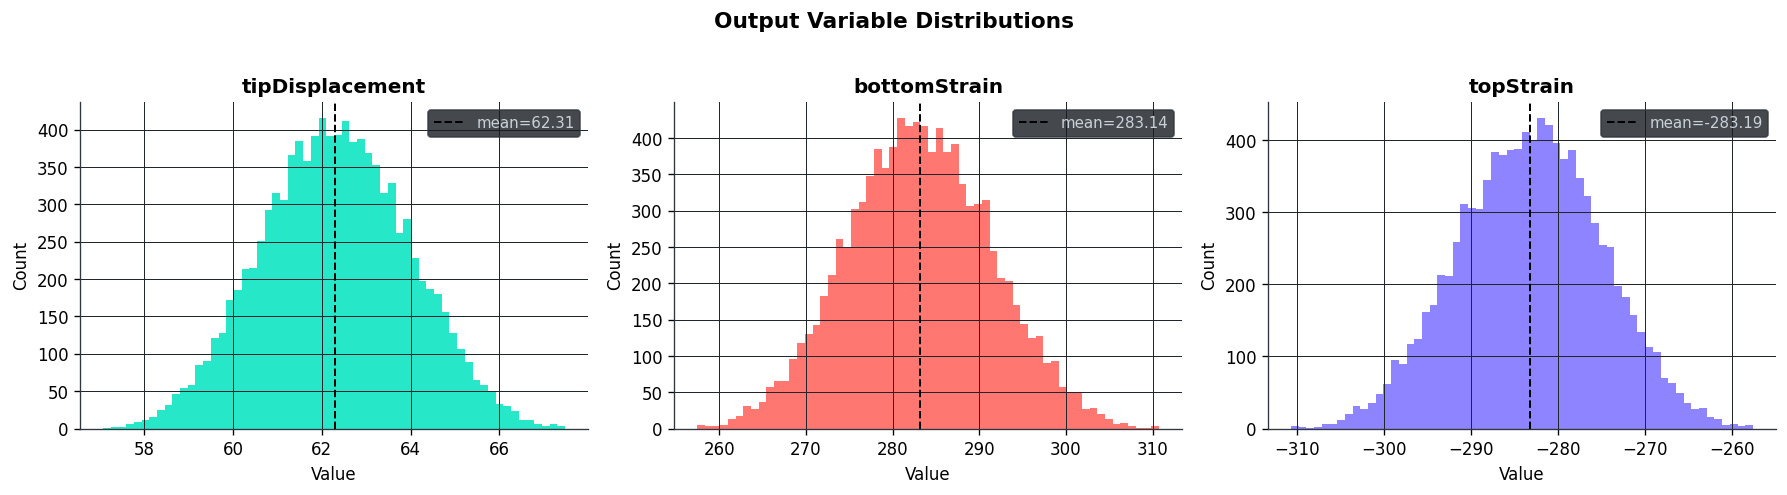

In [6]:
# ── Distribution of key output variables ─────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Output Variable Distributions', fontsize=13, 
             fontweight='bold', y=1.02, color='black')

output_cols = ['tipDisplacement', 'bottomStrain', 'topStrain']
colors = PALETTE[:3]

for ax, col, color in zip(axes, output_cols, colors):
    ax.hist(df[col], bins=60, color=color, alpha=0.85, edgecolor='none')
    ax.axvline(df[col].mean(), color='black', lw=1.2, linestyle='--', 
               label=f'mean={df[col].mean():.2f}')
    ax.set_title(col, fontweight='bold', color='black')
    ax.set_xlabel('Value', color='black')
    ax.set_ylabel('Count', color='black')
    ax.legend(fontsize=9)
    ax.set_facecolor('white')
    ax.tick_params(colors='black')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()


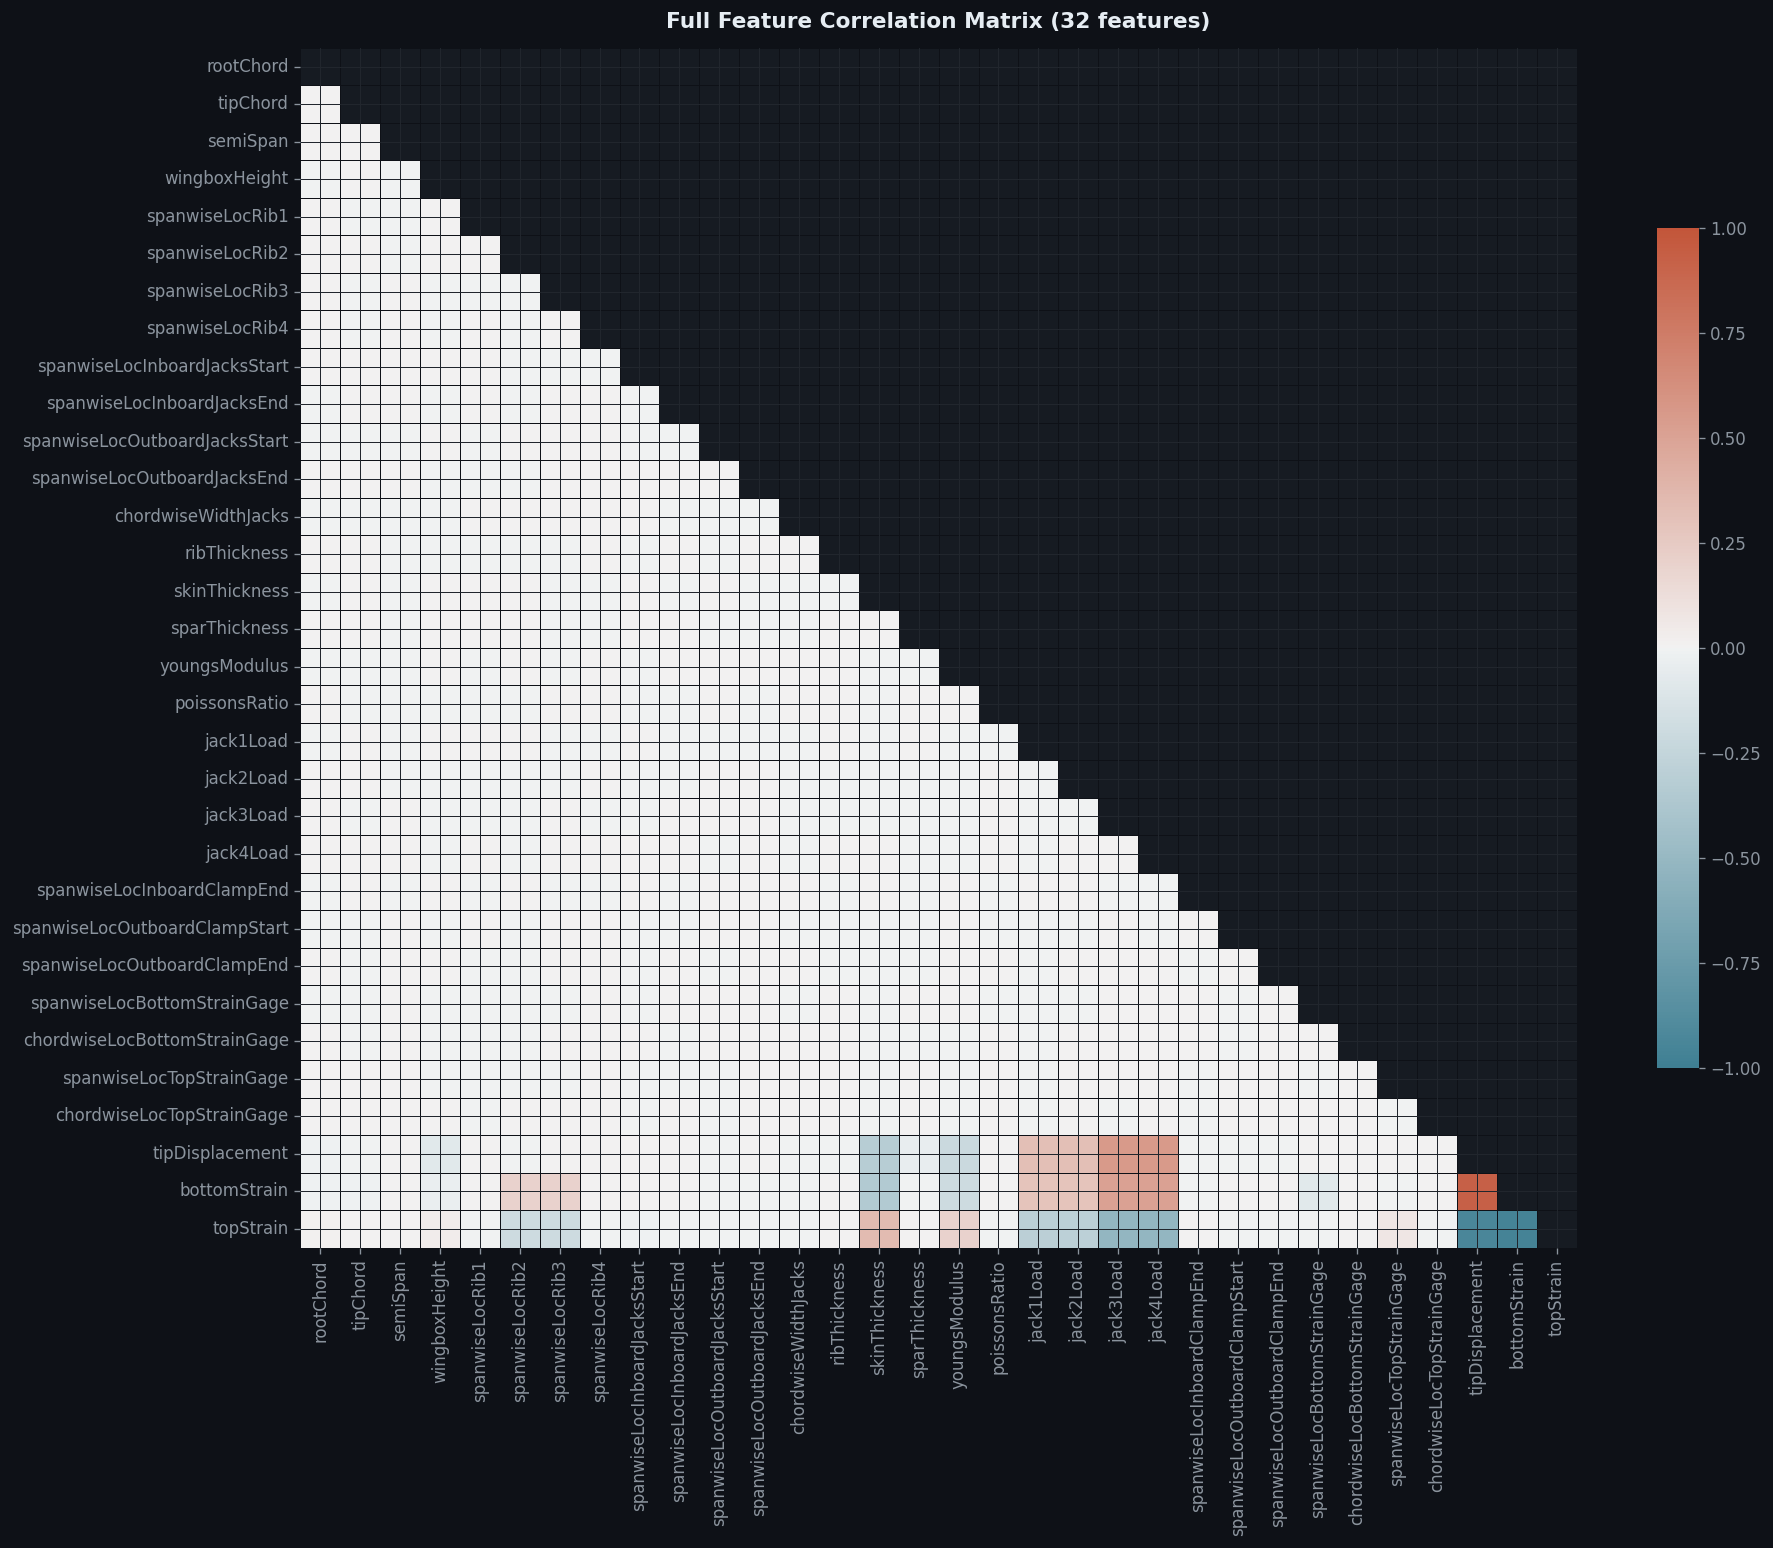

In [7]:
# ── Correlation heatmap (full 32 features) ───────────────────
fig, ax = plt.subplots(figsize=(16, 13))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(220, 20, as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, center=0, vmin=-1, vmax=1,
            linewidths=0.3, linecolor='#0e1117',
            cbar_kws={'shrink': 0.7}, ax=ax, annot=False)
ax.set_title('Full Feature Correlation Matrix (32 features)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


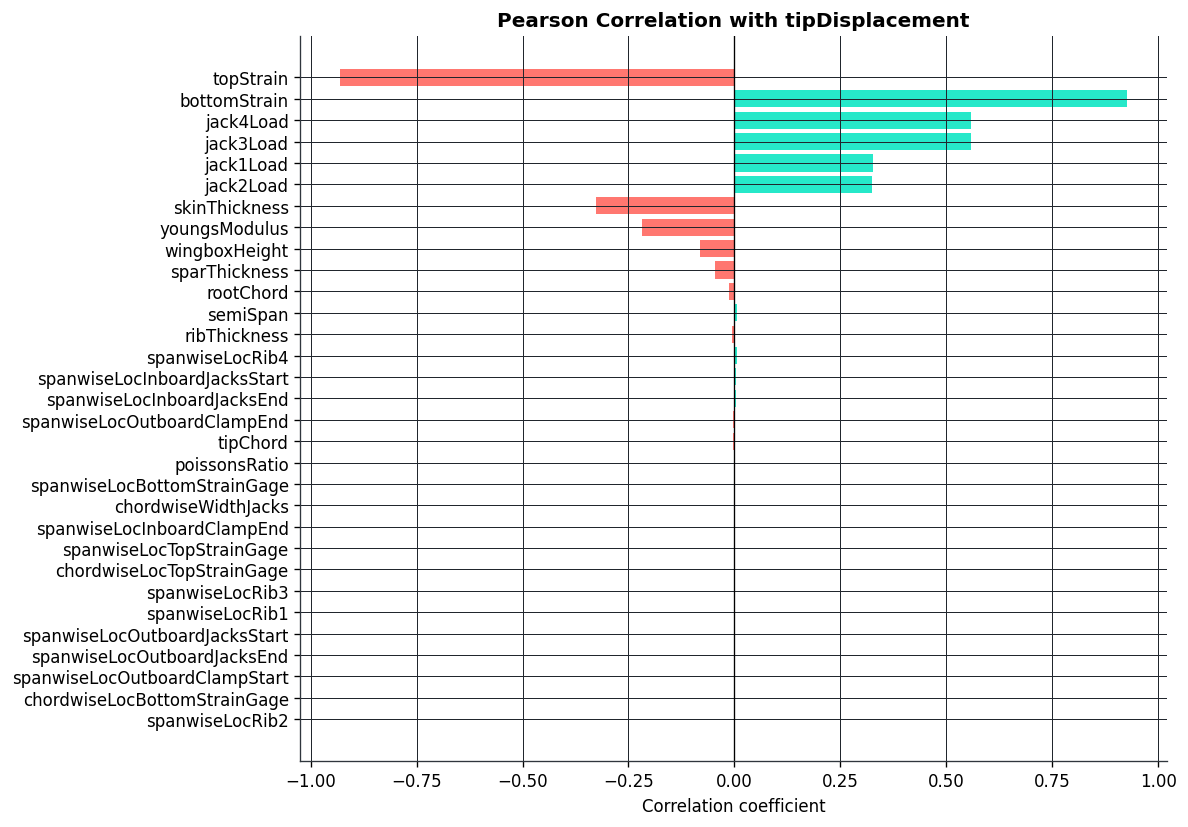


Top 8 correlated features:
topStrain       -0.9311
bottomStrain     0.9275
jack4Load        0.5589
jack3Load        0.5588
jack1Load        0.3276
jack2Load        0.3256
skinThickness   -0.3255
youngsModulus   -0.2179


In [8]:
# ── Top correlations with tipDisplacement ────────────────────
corr_td = df.corr()['tipDisplacement'].drop('tipDisplacement').sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
colors_bar = [PALETTE[0] if v > 0 else PALETTE[1] for v in corr_td.values]
bars = ax.barh(corr_td.index, corr_td.values, color=colors_bar, alpha=0.85, edgecolor='none')
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Pearson Correlation with tipDisplacement', fontsize=12, 
             fontweight='bold', color='black')
ax.set_xlabel('Correlation coefficient', color='black')
ax.invert_yaxis()
ax.set_facecolor('white')
ax.tick_params(colors='black')
fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

print("\nTop 8 correlated features:")
print(corr_td.head(8).round(4).to_string())

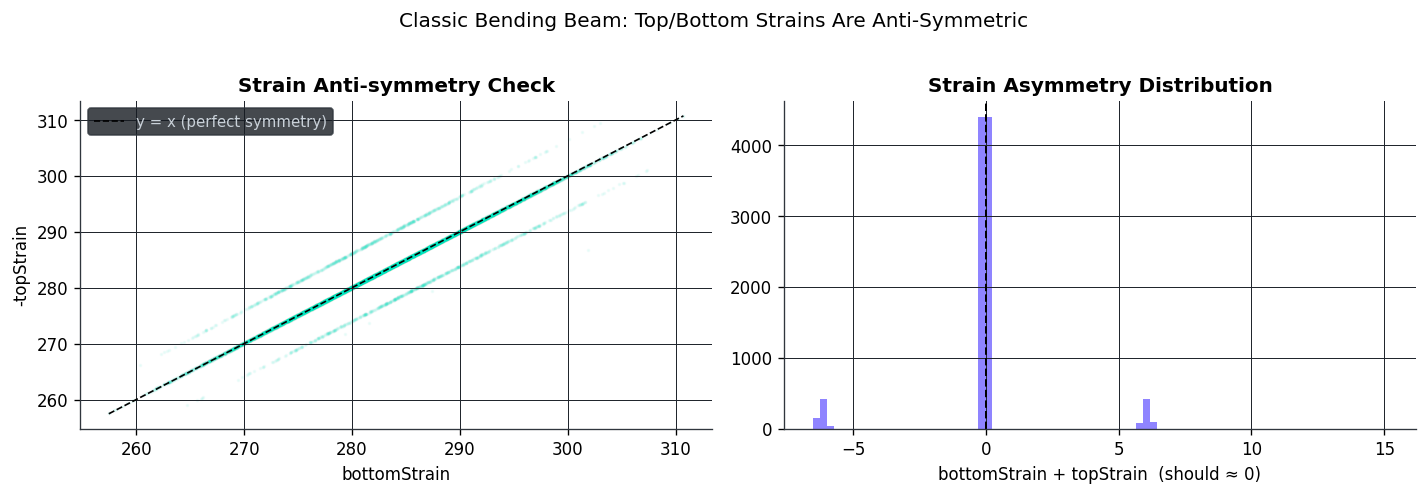

Strain asymmetry stats:
count    10001.00000
mean        -0.05153
std          2.12839
min         -6.51792
25%         -0.12888
50%          0.01589
75%          0.02830
max         15.11089
Name: strain_asymmetry_raw, dtype: float64


In [9]:
# ── Strain symmetry check ─────────────────────────────────────
df['strain_asymmetry_raw'] = df['bottomStrain'] + df['topStrain']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df['bottomStrain'], -df['topStrain'], alpha=0.05, s=1.5,
                color=PALETTE[0], rasterized=True)
lims = [df['bottomStrain'].min(), df['bottomStrain'].max()]
axes[0].plot(lims, lims, '--', color='black', lw=1, label='y = x (perfect symmetry)')
axes[0].set_xlabel('bottomStrain', color='black')
axes[0].set_ylabel('-topStrain', color='black')
axes[0].set_title('Strain Anti-symmetry Check', fontweight='bold', color='black')
axes[0].legend(fontsize=9)
axes[0].set_facecolor('white')
axes[0].tick_params(colors='black')

axes[1].hist(df['strain_asymmetry_raw'], bins=80, color=PALETTE[2], 
             alpha=0.85, edgecolor='none')
axes[1].axvline(0, color='black', lw=1.2, linestyle='--')
axes[1].set_xlabel('bottomStrain + topStrain  (should ≈ 0)', color='black')
axes[1].set_title('Strain Asymmetry Distribution', fontweight='bold', color='black')
axes[1].set_facecolor('white')
axes[1].tick_params(colors='black')

plt.suptitle('Classic Bending Beam: Top/Bottom Strains Are Anti-Symmetric', 
             fontsize=12, y=1.02, color='black')
fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

print(f"Strain asymmetry stats:")
print(df['strain_asymmetry_raw'].describe().round(5))
df.drop(columns='strain_asymmetry_raw', inplace=True)

In [10]:
# ── Group 1: Wing Geometry ────────────────────────────────────
df['taper_ratio']         = df['tipChord'] / df['rootChord']
df['aspect_ratio']        = (2 * df['semiSpan']) / ((df['rootChord'] + df['tipChord']) / 2)
df['wingbox_slenderness'] = df['semiSpan'] / df['wingboxHeight']
df['rib_span_coverage']   = (df['spanwiseLocRib4'] - df['spanwiseLocRib1']) / df['semiSpan']

# ── Group 2: Structural Material ─────────────────────────────
# Composite thickness: mean of rib, skin, spar
df['thickness_composite'] = (df['ribThickness'] + df['skinThickness'] + df['sparThickness']) / 3

# ── Group 3: Loading ──────────────────────────────────────────
df['total_load']    = df['jack1Load'] + df['jack2Load'] + df['jack3Load'] + df['jack4Load']
df['inboard_load']  = df['jack1Load'] + df['jack2Load']
df['outboard_load'] = df['jack3Load'] + df['jack4Load']
df['load_asymmetry']= df['inboard_load'] - df['outboard_load']

# ── Group 4: Structural Response ─────────────────────────────
df['strain_magnitude'] = (df['bottomStrain'].abs() + df['topStrain'].abs()) / 2
df['strain_asymmetry'] = df['bottomStrain'] + df['topStrain']   # ≈ 0 for symmetric bending

# ── Engineered feature set ────────────────────────────────────
ENG_COLS = [
    'taper_ratio', 'aspect_ratio', 'wingbox_slenderness', 'rib_span_coverage',
    'thickness_composite', 'youngsModulus', 'poissonsRatio',
    'total_load', 'inboard_load', 'outboard_load', 'load_asymmetry',
    'tipDisplacement', 'strain_magnitude', 'strain_asymmetry',
]

df_eng = df[ENG_COLS].copy()
print(f"Engineered feature matrix: {df_eng.shape}  ({df.shape[1] - len(ENG_COLS)} raw features dropped)")
df_eng.describe().round(4)


Engineered feature matrix: (10001, 14)  (29 raw features dropped)


,taper_ratio,aspect_ratio,wingbox_slenderness,rib_span_coverage,thickness_composite,youngsModulus,poissonsRatio,total_load,inboard_load,outboard_load,load_asymmetry,tipDisplacement,strain_magnitude,strain_asymmetry
count,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,1.000100e+04,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000,10001.0000
mean,0.5000,13.3333,50.0001,0.5400,8.0000,4.999993e+10,0.2000,9999.9020,9999.9698,-0.0677,10000.0375,62.3073,283.1690,-0.0515
std,0.0004,0.0059,0.0580,0.0001,0.0472,2.886767e+08,0.0012,173.1688,122.4746,122.5014,173.2797,1.6539,8.2122,2.1284
min,0.4990,13.3177,49.8912,0.5396,7.8667,4.950000e+10,0.1980,9400.0000,9700.0000,-300.0000,9495.5811,57.0721,257.5056,-6.5179
25%,0.4997,13.3288,49.9500,0.5399,7.9652,4.975000e+10,0.1990,9880.4687,9911.8164,-87.5977,9878.7842,61.1586,277.4784,-0.1289
50%,0.5000,13.3333,50.0001,0.5400,7.9998,5.000000e+10,0.2000,10000.2197,10000.0000,0.3662,10001.8311,62.3012,283.0554,0.0159
75%,0.5003,13.3379,50.0501,0.5401,8.0351,5.024988e+10,0.2010,10118.7988,10087.4512,87.6709,10118.4326,63.4492,288.8452,0.0283
max,0.5010,13.3486,50.1098,0.5404,8.1294,5.049988e+10,0.2020,10509.6191,10297.8027,297.7295,10563.5254,67.4743,310.7146,15.1109


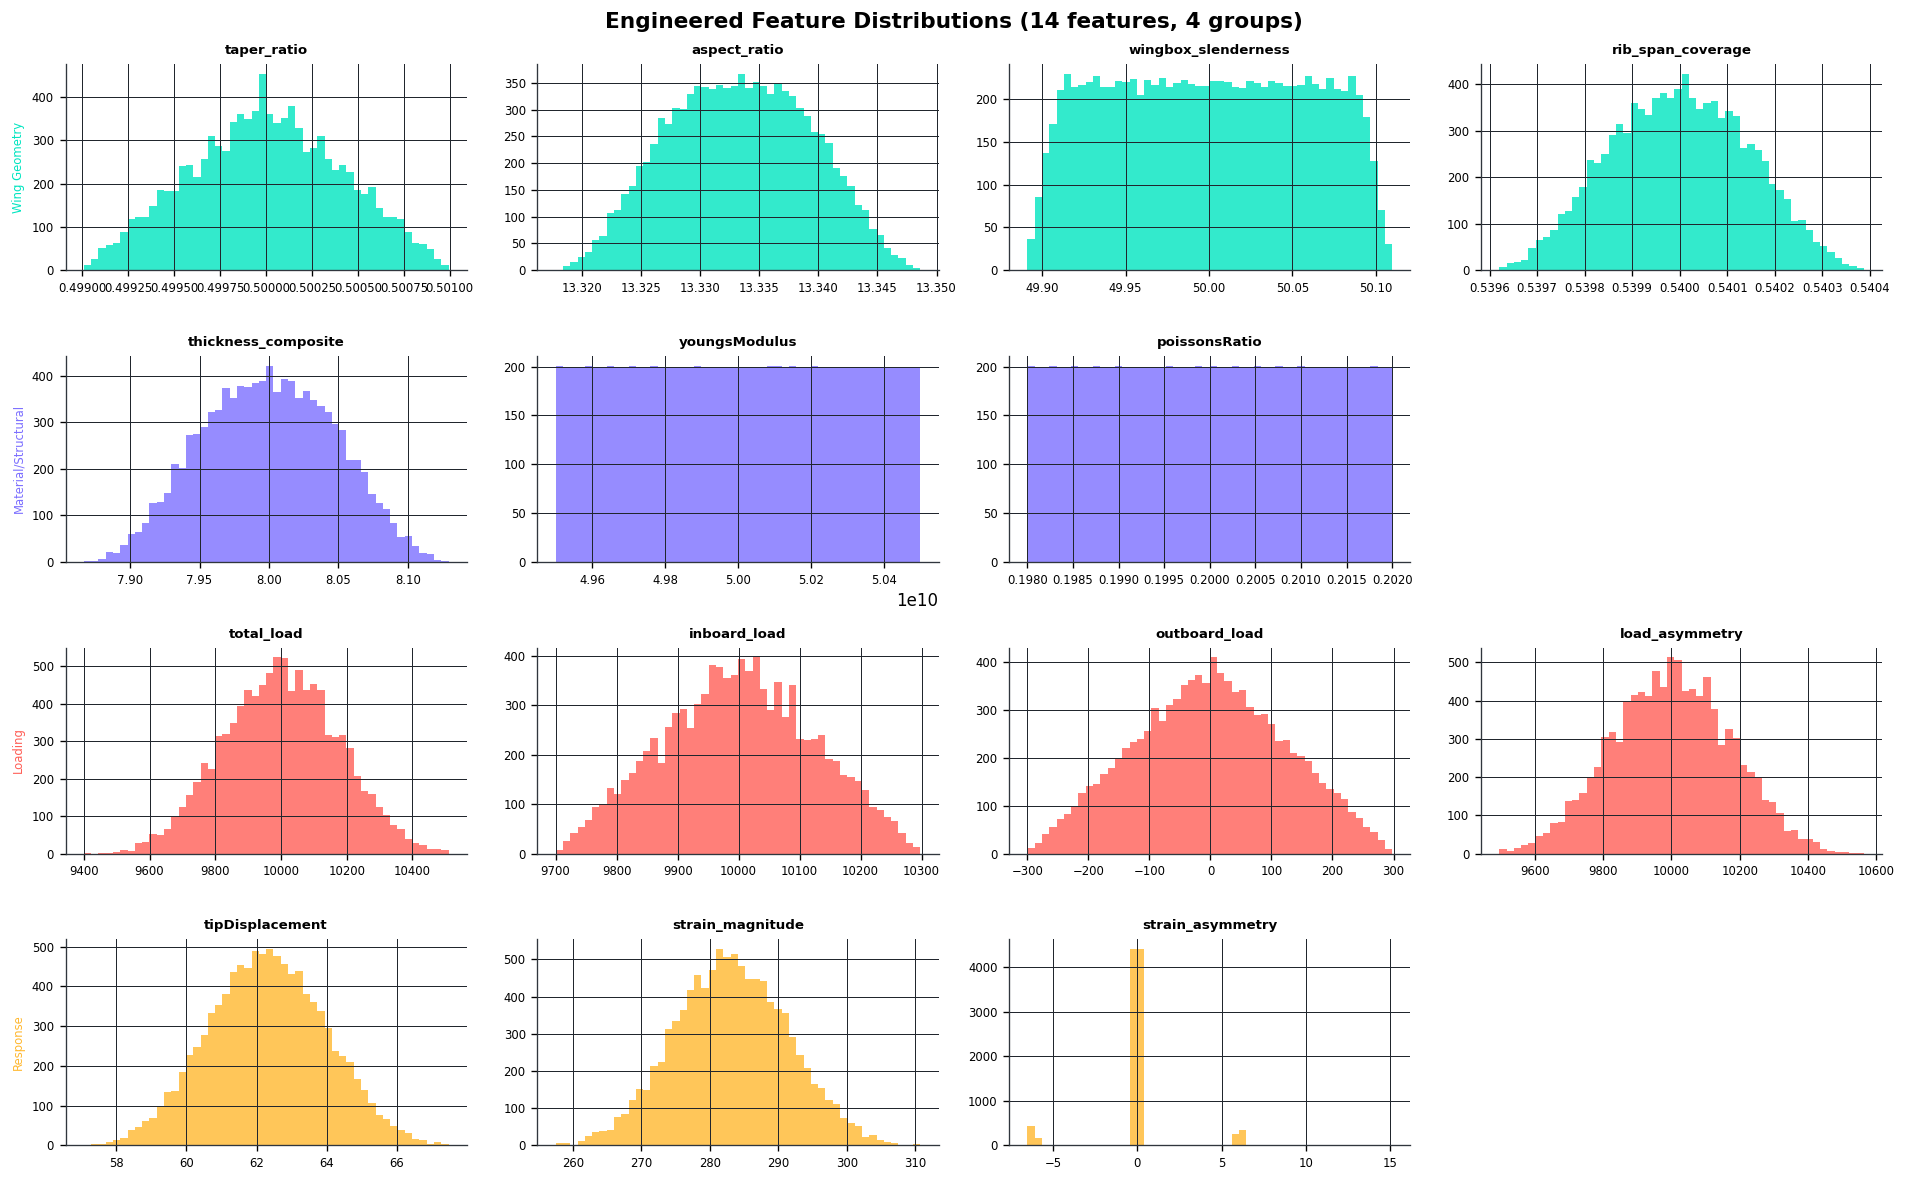

In [11]:
# ── Feature group overview plot ───────────────────────────────
GROUPS = {
    'Wing Geometry':      ['taper_ratio', 'aspect_ratio', 'wingbox_slenderness', 'rib_span_coverage'],
    'Material/Structural':['thickness_composite', 'youngsModulus', 'poissonsRatio'],
    'Loading':            ['total_load', 'inboard_load', 'outboard_load', 'load_asymmetry'],
    'Response':           ['tipDisplacement', 'strain_magnitude', 'strain_asymmetry'],
}
GROUP_COLORS = [PALETTE[0], PALETTE[2], PALETTE[1], PALETTE[3]]

fig, axes = plt.subplots(4, 4, figsize=(16, 10))
fig.suptitle('Engineered Feature Distributions (14 features, 4 groups)', 
             fontsize=13, fontweight='bold', color='black')

row = 0
for (grp, feats), color in zip(GROUPS.items(), GROUP_COLORS):
    for col_i, feat in enumerate(feats):
        ax = axes[row][col_i]
        ax.hist(df_eng[feat], bins=50, color=color, alpha=0.8, edgecolor='none')
        ax.set_title(feat, fontsize=8, fontweight='bold', color='black')
        ax.set_ylabel(grp if col_i == 0 else '', fontsize=7, color=color)
        ax.tick_params(labelsize=7, colors='black')
        ax.set_facecolor('white')
    # hide unused axes in the row
    for col_i in range(len(feats), 4):
        axes[row][col_i].axis('off')
    row += 1

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

In [12]:
scaler = StandardScaler()
X = scaler.fit_transform(df_eng)
print(f"X shape: {X.shape}")
print(f"Mean (should be ≈0): {X.mean(axis=0).round(6)}")
print(f"Std  (should be ≈1): {X.std(axis=0).round(4)}")


X shape: (10001, 14)
Mean (should be ≈0): [ 0.  0. -0.  0.  0. -0.  0.  0.  0. -0. -0.  0.  0.  0.]
Std  (should be ≈1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [13]:
# ── Full PCA ─────────────────────────────────────────────────
pca_full = PCA()
pca_full.fit(X)
evr  = pca_full.explained_variance_ratio_ * 100
cumv = np.cumsum(evr)

n_95 = np.searchsorted(cumv, 95) + 1
print(f"Components needed for 95% variance: {n_95}")
print(f"\nPer-component explained variance:")
for i, (e, c) in enumerate(zip(evr, cumv)):
    marker = " ◄ 95% threshold" if i + 1 == n_95 else ""
    print(f"  PC{i+1:2d}: {e:5.2f}%   cumulative: {c:5.2f}%{marker}")


Components needed for 95% variance: 10

Per-component explained variance:
  PC 1: 27.00%   cumulative: 27.00%
  PC 2: 14.29%   cumulative: 41.29%
  PC 3:  9.49%   cumulative: 50.77%
  PC 4:  7.84%   cumulative: 58.62%
  PC 5:  7.42%   cumulative: 66.04%
  PC 6:  7.19%   cumulative: 73.22%
  PC 7:  7.15%   cumulative: 80.38%
  PC 8:  7.12%   cumulative: 87.49%
  PC 9:  6.84%   cumulative: 94.33%
  PC10:  4.81%   cumulative: 99.14% ◄ 95% threshold
  PC11:  0.76%   cumulative: 99.90%
  PC12:  0.10%   cumulative: 100.00%
  PC13:  0.00%   cumulative: 100.00%
  PC14:  0.00%   cumulative: 100.00%


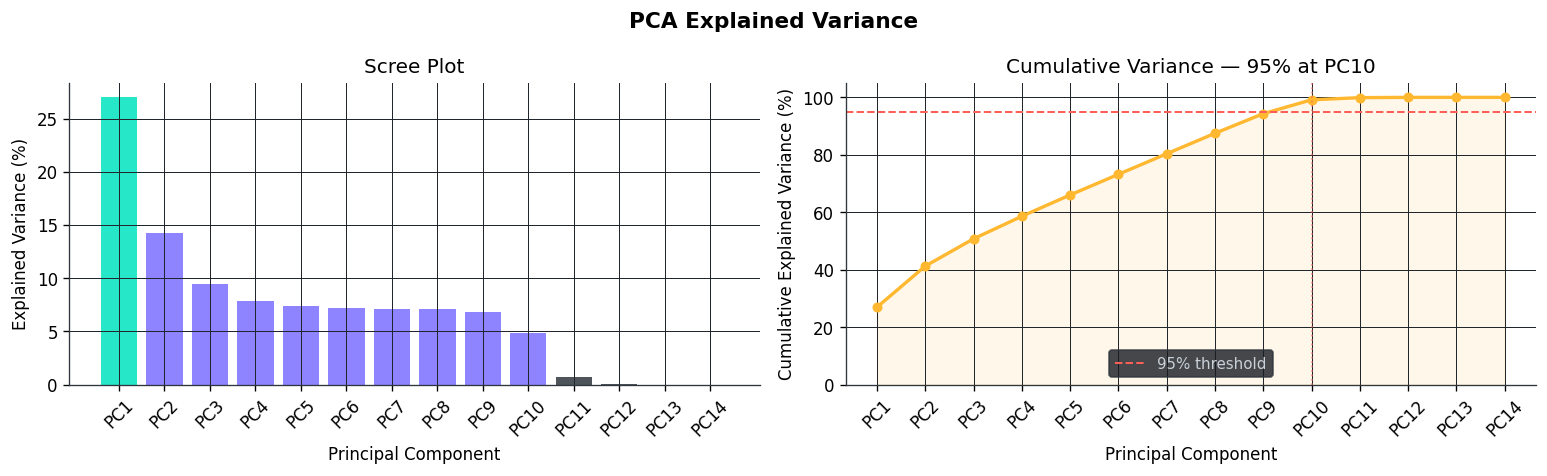

In [14]:
# ── Scree + cumulative variance plot ─────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('PCA Explained Variance', fontsize=13, 
             fontweight='bold', color='black')

pcs = [f'PC{i+1}' for i in range(len(evr))]

# Scree
bar_colors = [PALETTE[0] if i == 0 else PALETTE[2] if i < n_95 else '#30363d' for i in range(len(evr))]
ax1.bar(pcs, evr, color=bar_colors, alpha=0.85, edgecolor='none')
ax1.set_xlabel('Principal Component', color='black')
ax1.set_ylabel('Explained Variance (%)', color='black')
ax1.set_title('Scree Plot', color='black')
ax1.tick_params(axis='x', rotation=45, colors='black')
ax1.tick_params(axis='y', colors='black')
ax1.set_facecolor('white')

# Cumulative
ax2.plot(pcs, cumv, color=PALETTE[3], lw=2, marker='o', markersize=5)
ax2.fill_between(pcs, cumv, alpha=0.1, color=PALETTE[3])
ax2.axhline(95, color=PALETTE[1], lw=1.2, linestyle='--', label='95% threshold')
ax2.axvline(f'PC{n_95}', color=PALETTE[1], lw=1, linestyle=':', alpha=0.7)
ax2.set_xlabel('Principal Component', color='black')
ax2.set_ylabel('Cumulative Explained Variance (%)', color='black')
ax2.set_title(f'Cumulative Variance — 95% at PC{n_95}', color='black')
ax2.legend(fontsize=9)
ax2.set_ylim(0, 105)
ax2.tick_params(axis='x', rotation=45, colors='black')
ax2.tick_params(axis='y', colors='black')
ax2.set_facecolor('white')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

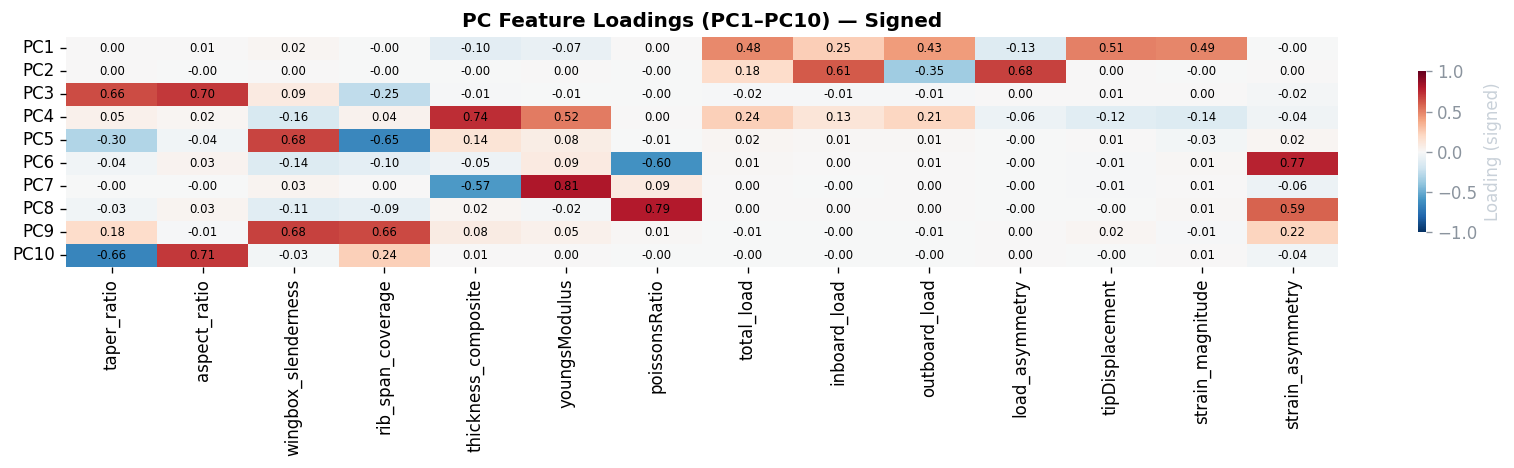


Top 4 features per PC:
  PC1: {'tipDisplacement': np.float64(0.507), 'strain_magnitude': np.float64(0.489), 'total_load': np.float64(0.477), 'outboard_load': np.float64(0.427)}
  PC2: {'load_asymmetry': np.float64(0.683), 'inboard_load': np.float64(0.612), 'outboard_load': np.float64(0.355), 'total_load': np.float64(0.182)}
  PC3: {'aspect_ratio': np.float64(0.704), 'taper_ratio': np.float64(0.656), 'rib_span_coverage': np.float64(0.253), 'wingbox_slenderness': np.float64(0.091)}
  PC4: {'thickness_composite': np.float64(0.736), 'youngsModulus': np.float64(0.522), 'total_load': np.float64(0.239), 'outboard_load': np.float64(0.213)}
  PC5: {'wingbox_slenderness': np.float64(0.679), 'rib_span_coverage': np.float64(0.649), 'taper_ratio': np.float64(0.3), 'thickness_composite': np.float64(0.14)}
  PC6: {'strain_asymmetry': np.float64(0.771), 'poissonsRatio': np.float64(0.603), 'wingbox_slenderness': np.float64(0.136), 'rib_span_coverage': np.float64(0.096)}
  PC7: {'youngsModulus': np.flo

In [38]:
# ── PC Loading heatmap (signed) ───────────────────────────────
pca5 = PCA(n_components=10)
pca5.fit(X)
loadings = pd.DataFrame(pca5.components_, columns=ENG_COLS,
                        index=[f'PC{i+1}' for i in range(10)])

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(loadings, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            ax=ax, annot=loadings.round(2),
            fmt='.2f', linewidths=0,
            cbar_kws={'label': 'Loading (signed)', 'shrink': 0.7},
            annot_kws={'size': 7, 'color': 'black'})
ax.set_title('PC Feature Loadings (PC1–PC10) — Signed', fontsize=12, 
             fontweight='bold', color='black')
ax.set_xlabel('', color='black')
ax.tick_params(colors='black')
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# Remove all remaining grid lines
for _, spine in ax.spines.items():
    spine.set_visible(False)
ax.grid(False)

plt.tight_layout()
plt.show()

print("\nTop 4 features per PC:")
for pc in loadings.index:
    top = loadings.loc[pc].abs().sort_values(ascending=False).head(4)
    print(f"  {pc}: {dict(zip(top.index, top.round(3).values))}")

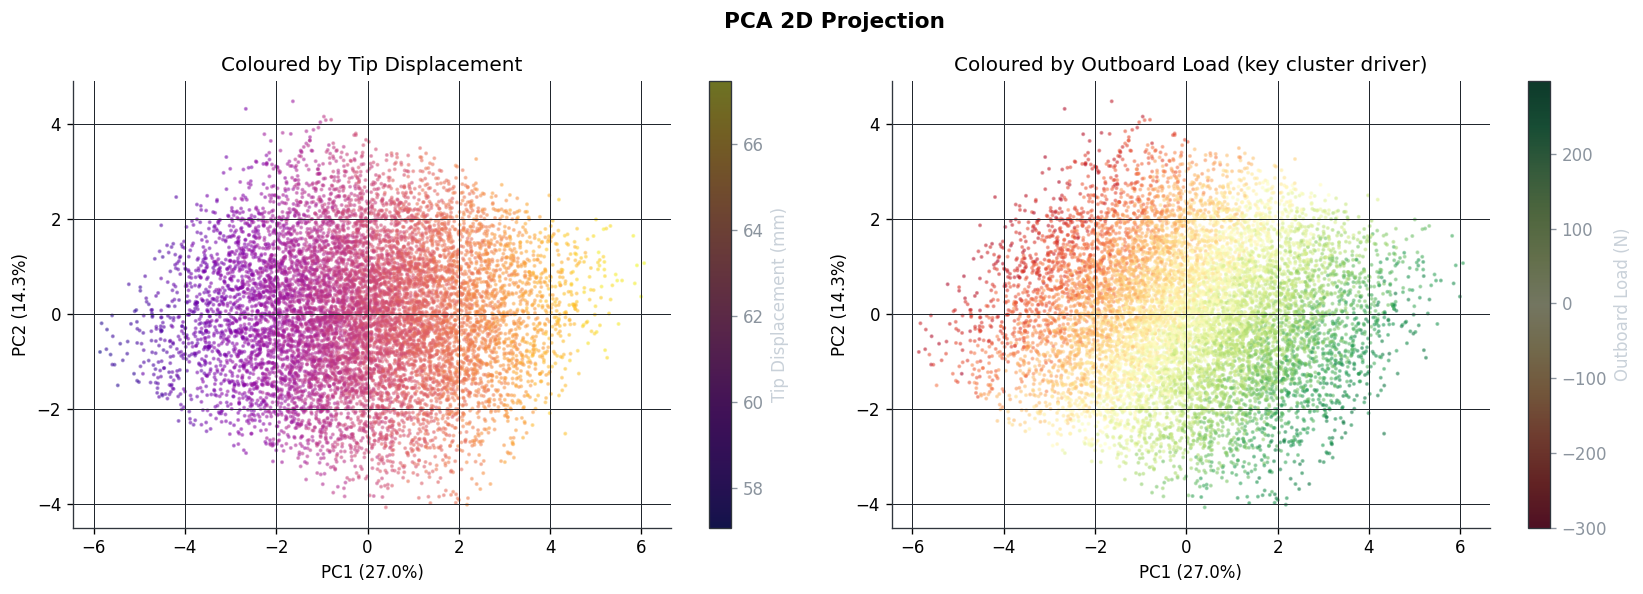

In [16]:
# ── PCA 2D scatter ────────────────────────────────────────────
pca2  = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X)
var2  = pca2.explained_variance_ratio_ * 100

# Colour by tipDisplacement for initial view
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('PCA 2D Projection', fontsize=13, fontweight='bold', color='black')

sc1 = axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1],
                       c=df_eng['tipDisplacement'], cmap='plasma',
                       s=2, alpha=0.4, rasterized=True)
plt.colorbar(sc1, ax=axes[0], label='Tip Displacement (mm)')
axes[0].set_xlabel(f'PC1 ({var2[0]:.1f}%)', color='black')
axes[0].set_ylabel(f'PC2 ({var2[1]:.1f}%)', color='black')
axes[0].set_title('Coloured by Tip Displacement', color='black')
axes[0].set_facecolor('white')
axes[0].tick_params(colors='black')

sc2 = axes[1].scatter(X_pca2[:, 0], X_pca2[:, 1],
                       c=df_eng['outboard_load'], cmap='RdYlGn',
                       s=2, alpha=0.4, rasterized=True)
plt.colorbar(sc2, ax=axes[1], label='Outboard Load (N)')
axes[1].set_xlabel(f'PC1 ({var2[0]:.1f}%)', color='black')
axes[1].set_ylabel(f'PC2 ({var2[1]:.1f}%)', color='black')
axes[1].set_title('Coloured by Outboard Load (key cluster driver)', color='black')
axes[1].set_facecolor('white')
axes[1].tick_params(colors='black')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

In [17]:
# ── Fit t-SNE ─────────────────────────────────────────────────
pca10   = PCA(n_components=10)
X_pca10 = pca10.fit_transform(X)

np.random.seed(42)
tsne_idx = np.random.choice(len(X_pca10), 3000, replace=False)
X_tsne_in = X_pca10[tsne_idx]

print("Fitting t-SNE on 3,000 samples (perplexity=50) ...")
tsne = TSNE(n_components=2, perplexity=50, max_iter=1000, random_state=42, n_jobs=-1)
X_tsne = tsne.fit_transform(X_tsne_in)
print(f"Done. t-SNE output shape: {X_tsne.shape}")


Fitting t-SNE on 3,000 samples (perplexity=50) ...
Done. t-SNE output shape: (3000, 2)


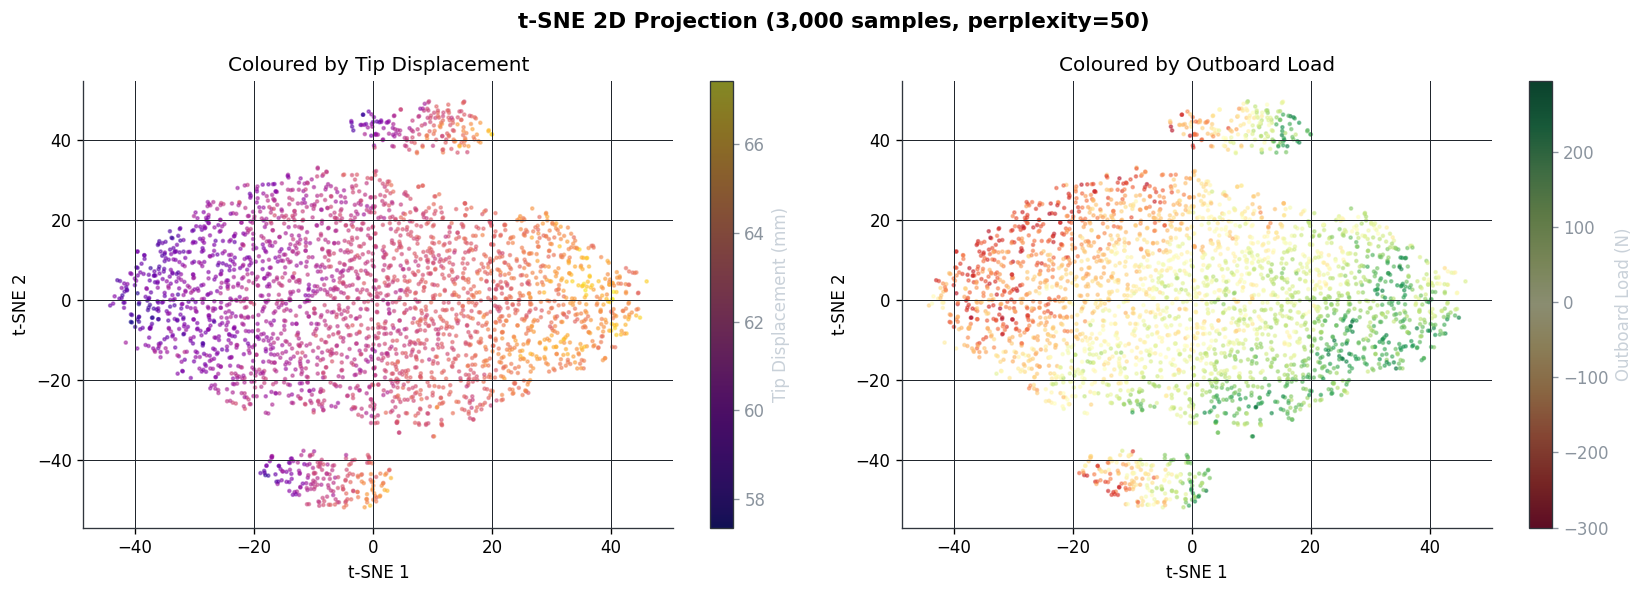

In [18]:
# ── t-SNE scatter ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('t-SNE 2D Projection (3,000 samples, perplexity=50)', fontsize=13, 
             fontweight='bold', color='black')

sc1 = axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1],
                       c=df_eng['tipDisplacement'].values[tsne_idx], cmap='plasma',
                       s=3, alpha=0.5, rasterized=True)
plt.colorbar(sc1, ax=axes[0], label='Tip Displacement (mm)')
axes[0].set_title('Coloured by Tip Displacement', color='black')
axes[0].set_xlabel('t-SNE 1', color='black')
axes[0].set_ylabel('t-SNE 2', color='black')
axes[0].set_facecolor('white')
axes[0].tick_params(colors='black')

sc2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1],
                       c=df_eng['outboard_load'].values[tsne_idx], cmap='RdYlGn',
                       s=3, alpha=0.5, rasterized=True)
plt.colorbar(sc2, ax=axes[1], label='Outboard Load (N)')
axes[1].set_title('Coloured by Outboard Load', color='black')
axes[1].set_xlabel('t-SNE 1', color='black')
axes[1].set_ylabel('t-SNE 2', color='black')
axes[1].set_facecolor('white')
axes[1].tick_params(colors='black')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

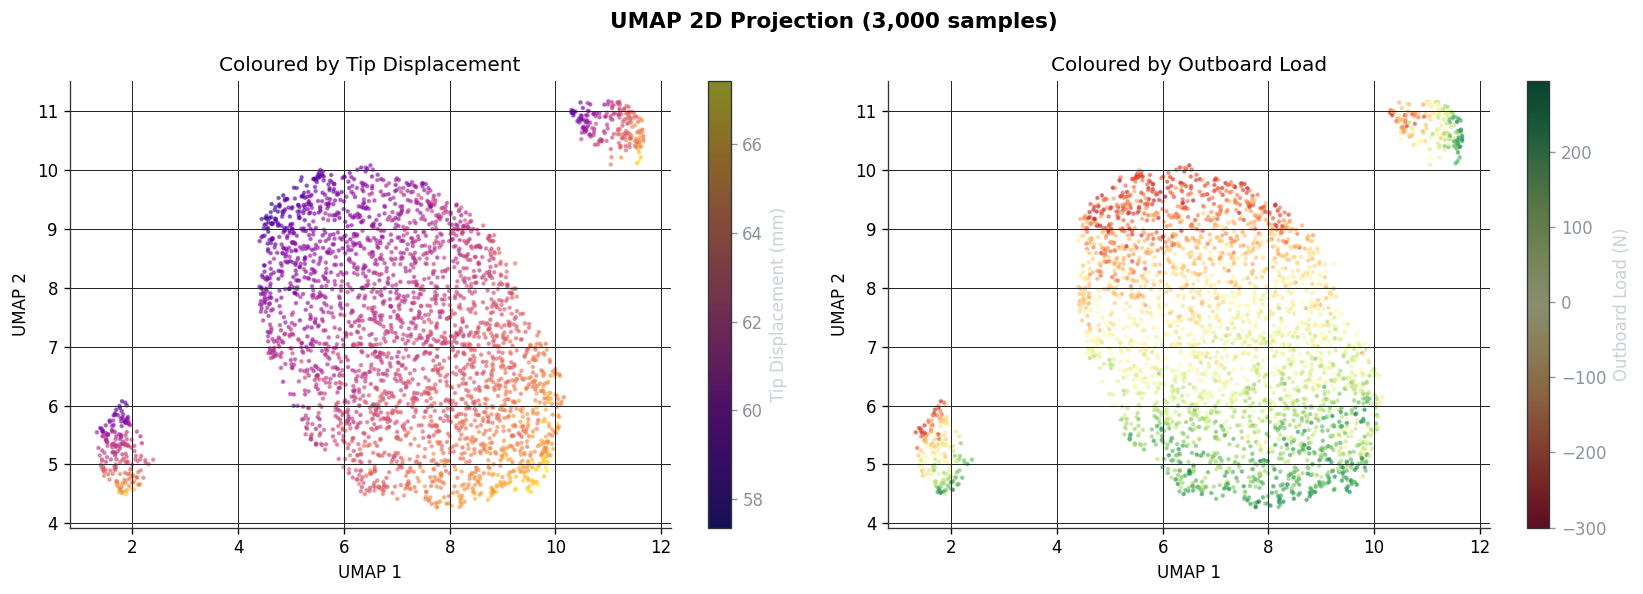

In [19]:
if UMAP_AVAILABLE:
    reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
    X_umap = reducer.fit_transform(X_pca10[tsne_idx])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('UMAP 2D Projection (3,000 samples)', fontsize=13, 
                 fontweight='bold', color='black')

    sc1 = axes[0].scatter(X_umap[:, 0], X_umap[:, 1],
                           c=df_eng['tipDisplacement'].values[tsne_idx], cmap='plasma',
                           s=3, alpha=0.5, rasterized=True)
    plt.colorbar(sc1, ax=axes[0], label='Tip Displacement (mm)')
    axes[0].set_title('Coloured by Tip Displacement', color='black')
    axes[0].set_xlabel('UMAP 1', color='black')
    axes[0].set_ylabel('UMAP 2', color='black')
    axes[0].set_facecolor('white')
    axes[0].tick_params(colors='black')

    sc2 = axes[1].scatter(X_umap[:, 0], X_umap[:, 1],
                           c=df_eng['outboard_load'].values[tsne_idx], cmap='RdYlGn',
                           s=3, alpha=0.5, rasterized=True)
    plt.colorbar(sc2, ax=axes[1], label='Outboard Load (N)')
    axes[1].set_title('Coloured by Outboard Load', color='black')
    axes[1].set_xlabel('UMAP 1', color='black')
    axes[1].set_ylabel('UMAP 2', color='black')
    axes[1].set_facecolor('white')
    axes[1].tick_params(colors='black')

    fig.patch.set_facecolor('white')
    plt.tight_layout()
    plt.show()
else:
    print("Skipping UMAP — not installed.")
    print("Install with: pip install umap-learn")

In [20]:
# ── Silhouette sweep k=2..8 ───────────────────────────────────
sil_scores = {}
inertias   = {}

print("Sweeping k=2..8 on PCA-10 space ...")
for k in range(2, 9):
    km  = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_pca10)
    sil = silhouette_score(X_pca10, lbl, sample_size=3000, random_state=42)
    sil_scores[k] = round(sil, 4)
    inertias[k]   = round(km.inertia_, 1)
    print(f"  k={k}: silhouette={sil:.4f}   inertia={km.inertia_:.1f}")

best_k = max(sil_scores, key=sil_scores.get)
print(f"\nBest k by silhouette: {best_k}  ({sil_scores[best_k]})")


Sweeping k=2..8 on PCA-10 space ...
  k=2: silhouette=0.1575   inertia=114060.8
  k=3: silhouette=0.1107   inertia=105594.6
  k=4: silhouette=0.1043   inertia=99026.3
  k=5: silhouette=0.0967   inertia=95470.2
  k=6: silhouette=0.0985   inertia=92385.3
  k=7: silhouette=0.0839   inertia=89722.1
  k=8: silhouette=0.0795   inertia=87711.8

Best k by silhouette: 2  (0.1575)


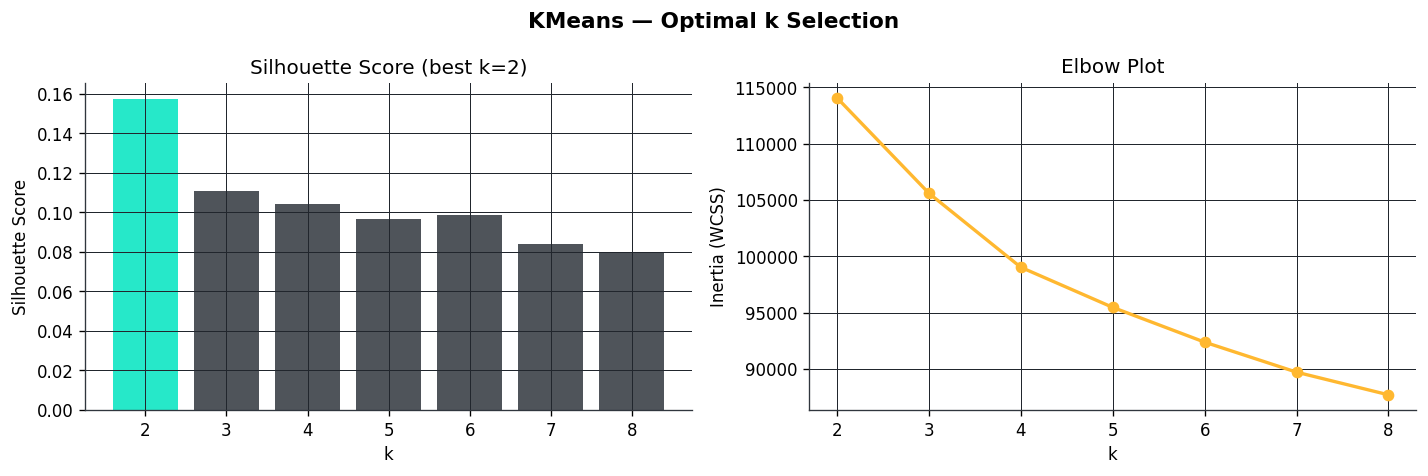

In [21]:
# ── Silhouette + Elbow plot ───────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('KMeans — Optimal k Selection', fontsize=13, 
             fontweight='bold', color='black')

ks = list(sil_scores.keys())
sils = list(sil_scores.values())
bar_colors = [PALETTE[0] if k == best_k else '#30363d' for k in ks]

ax1.bar(ks, sils, color=bar_colors, alpha=0.85, edgecolor='none')
ax1.set_xlabel('k', color='black')
ax1.set_ylabel('Silhouette Score', color='black')
ax1.set_title(f'Silhouette Score (best k={best_k})', color='black')
ax1.set_xticks(ks)
ax1.set_facecolor('white')
ax1.tick_params(colors='black')

ax2.plot(ks, [inertias[k] for k in ks], color=PALETTE[3], lw=2, 
         marker='o', markersize=6)
ax2.set_xlabel('k', color='black')
ax2.set_ylabel('Inertia (WCSS)', color='black')
ax2.set_title('Elbow Plot', color='black')
ax2.set_xticks(ks)
ax2.set_facecolor('white')
ax2.tick_params(colors='black')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

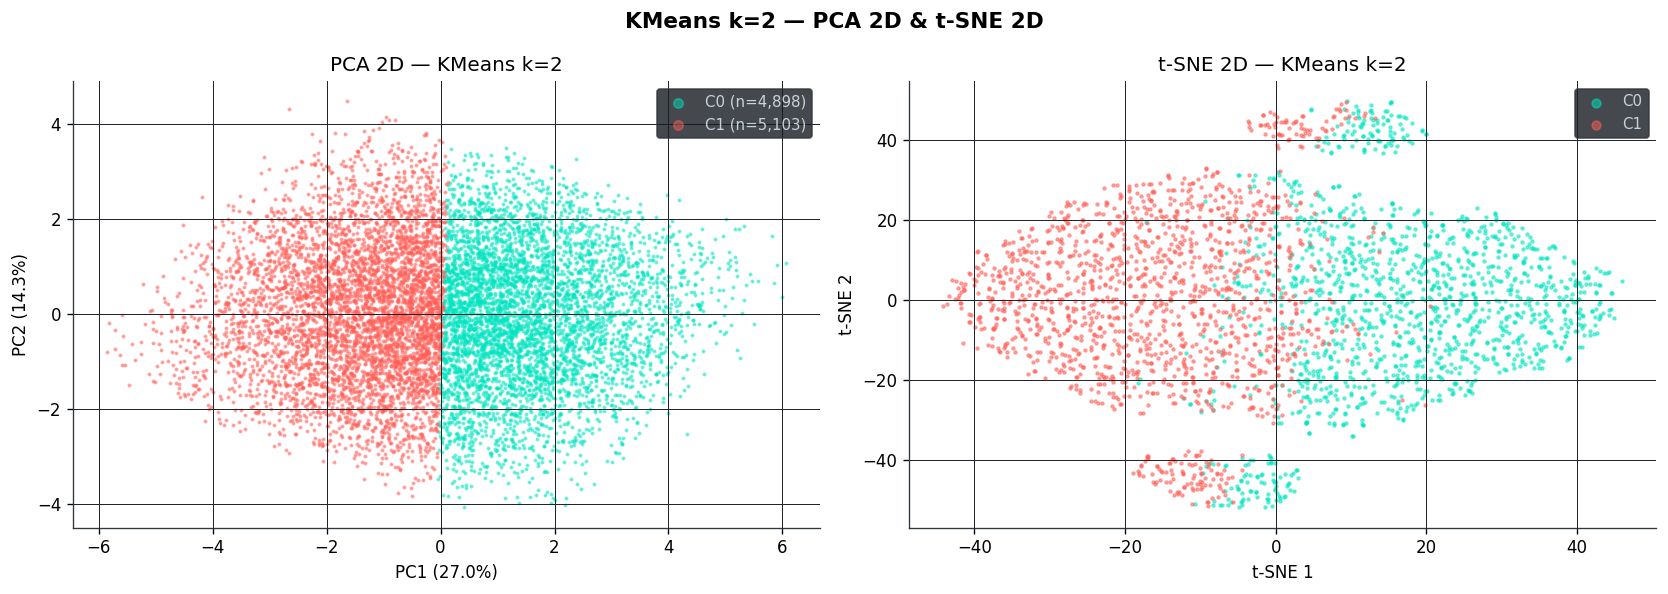

In [22]:
# ── Fit best KMeans + visualise on PCA-2D ────────────────────
km_best   = KMeans(n_clusters=best_k, random_state=42, n_init=10)
km_labels = km_best.fit_predict(X_pca10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'KMeans k={best_k} — PCA 2D & t-SNE 2D', fontsize=13, 
             fontweight='bold', color='black')

# PCA
for c in range(best_k):
    mask = km_labels == c
    axes[0].scatter(X_pca2[mask, 0], X_pca2[mask, 1],
                    color=PALETTE[c % len(PALETTE)], s=2, alpha=0.45,
                    label=f'C{c} (n={mask.sum():,})', rasterized=True)
axes[0].set_xlabel(f'PC1 ({var2[0]:.1f}%)', color='black')
axes[0].set_ylabel(f'PC2 ({var2[1]:.1f}%)', color='black')
axes[0].set_title(f'PCA 2D — KMeans k={best_k}', color='black')
axes[0].legend(markerscale=4, fontsize=9)
axes[0].set_facecolor('white')
axes[0].tick_params(colors='black')

# t-SNE
km_tsne_labels = km_labels[tsne_idx]
for c in range(best_k):
    mask = km_tsne_labels == c
    axes[1].scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                    color=PALETTE[c % len(PALETTE)], s=3, alpha=0.5,
                    label=f'C{c}', rasterized=True)
axes[1].set_xlabel('t-SNE 1', color='black')
axes[1].set_ylabel('t-SNE 2', color='black')
axes[1].set_title(f't-SNE 2D — KMeans k={best_k}', color='black')
axes[1].legend(markerscale=3, fontsize=9)
axes[1].set_facecolor('white')
axes[1].tick_params(colors='black')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

In [23]:
# ── KMeans cluster profile ────────────────────────────────────
df_eng['km_cluster'] = km_labels
profile_km = df_eng.groupby('km_cluster')[ENG_COLS].mean().round(4)
print(f"KMeans k={best_k} — Cluster Mean Profile:")
profile_km.T


KMeans k=2 — Cluster Mean Profile:


km_cluster,0,1
taper_ratio,5.000000e-01,5.000000e-01
aspect_ratio,1.333340e+01,1.333330e+01
wingbox_slenderness,5.000210e+01,4.999810e+01
rib_span_coverage,5.400000e-01,5.400000e-01
thickness_composite,7.993000e+00,8.006700e+00
youngsModulus,4.996558e+10,5.003290e+10
poissonsRatio,2.000000e-01,2.000000e-01
total_load,1.013144e+04,9.873649e+03
inboard_load,1.004484e+04,9.956902e+03
outboard_load,8.659930e+01,-8.325310e+01


In [24]:
# ── 4-cluster on load+response subspace ──────────────────────
LR_COLS = ['total_load', 'inboard_load', 'outboard_load', 'load_asymmetry',
           'tipDisplacement', 'strain_magnitude', 'strain_asymmetry']

X_lr     = StandardScaler().fit_transform(df_eng[LR_COLS])
km4_lr   = KMeans(n_clusters=4, random_state=42, n_init=10)
labels4  = km4_lr.fit_predict(X_lr)
df_eng['lr_cluster'] = labels4

LR_NAMES = {0: 'High Out+', 1: 'High Out−', 2: 'Low Out+', 3: 'Low Out−'}

print("Load-Regime Cluster Sizes:")
for c, name in LR_NAMES.items():
    print(f"  C{c} [{name}]: {(labels4==c).sum():,}")


Load-Regime Cluster Sizes:
  C0 [High Out+]: 2,339
  C1 [High Out−]: 2,257
  C2 [Low Out+]: 2,637
  C3 [Low Out−]: 2,768


In [25]:
# ── Load-regime profile table ─────────────────────────────────
profile_lr = df_eng.groupby('lr_cluster')[LR_COLS].mean().round(3)
profile_lr.index = [f"C{c}: {LR_NAMES[c]}" for c in profile_lr.index]
print("Load-Regime Cluster Mean Profile:")
profile_lr.T


Load-Regime Cluster Mean Profile:


,C0: High Out+,C1: High Out−,C2: Low Out+,C3: Low Out−
total_load,10213.954,9781.023,9969.831,10026.145
inboard_load,10088.202,9908.839,9898.867,10096.037
outboard_load,125.752,-127.817,70.964,-69.892
load_asymmetry,9962.450,10036.656,9827.903,10165.929
tipDisplacement,64.378,60.211,62.434,62.145
strain_magnitude,293.097,273.248,283.767,282.299
strain_asymmetry,-0.142,0.002,-0.006,-0.062


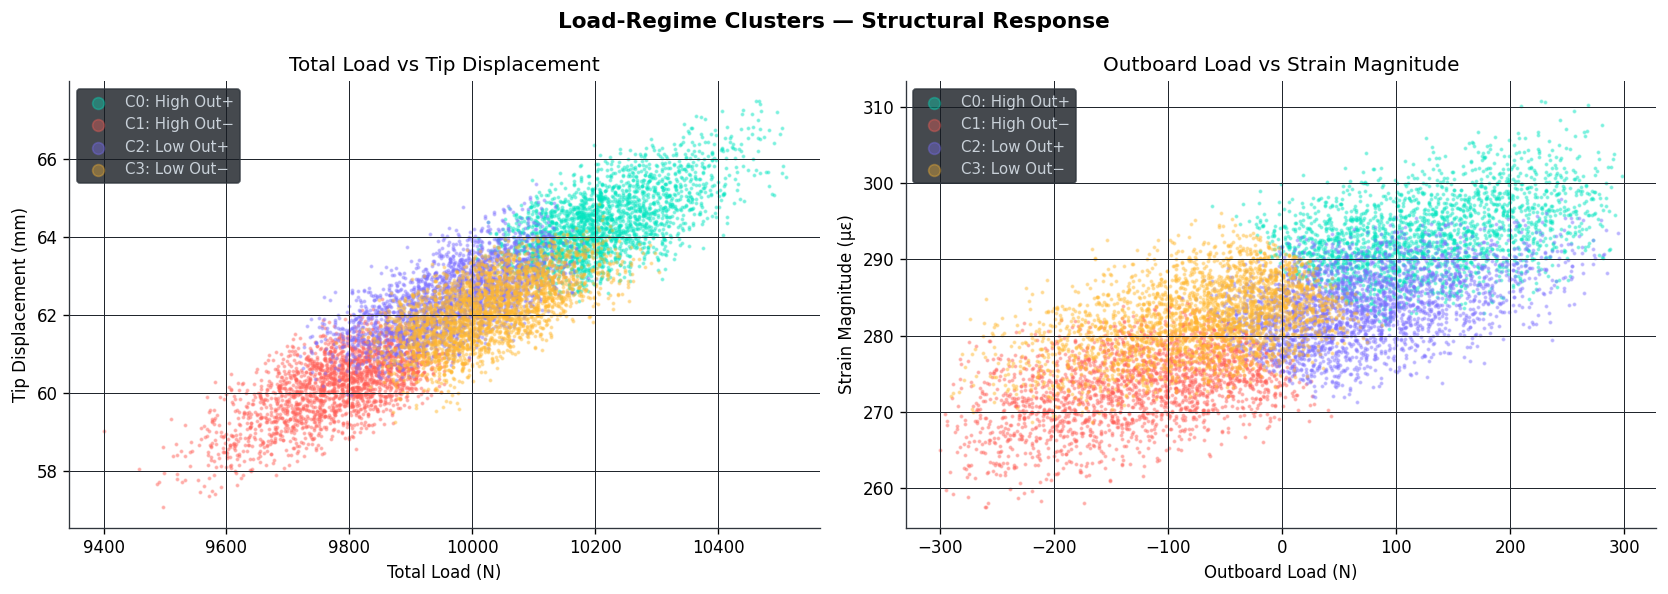

In [26]:
# ── Scatter: Total Load vs Tip Displacement by cluster ────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Load-Regime Clusters — Structural Response', fontsize=13, 
             fontweight='bold', color='black')

for c in range(4):
    mask = labels4 == c
    col  = PALETTE[c]
    name = LR_NAMES[c]
    axes[0].scatter(df_eng.loc[mask, 'total_load'],
                    df_eng.loc[mask, 'tipDisplacement'],
                    color=col, s=2, alpha=0.35, label=f'C{c}: {name}', rasterized=True)
    axes[1].scatter(df_eng.loc[mask, 'outboard_load'],
                    df_eng.loc[mask, 'strain_magnitude'],
                    color=col, s=2, alpha=0.35, label=f'C{c}: {name}', rasterized=True)

axes[0].set_xlabel('Total Load (N)', color='black')
axes[0].set_ylabel('Tip Displacement (mm)', color='black')
axes[0].set_title('Total Load vs Tip Displacement', color='black')
axes[0].legend(markerscale=5, fontsize=9)
axes[0].set_facecolor('white')
axes[0].tick_params(colors='black')

axes[1].set_xlabel('Outboard Load (N)', color='black')
axes[1].set_ylabel('Strain Magnitude (με)', color='black')
axes[1].set_title('Outboard Load vs Strain Magnitude', color='black')
axes[1].legend(markerscale=5, fontsize=9)
axes[1].set_facecolor('white')
axes[1].tick_params(colors='black')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

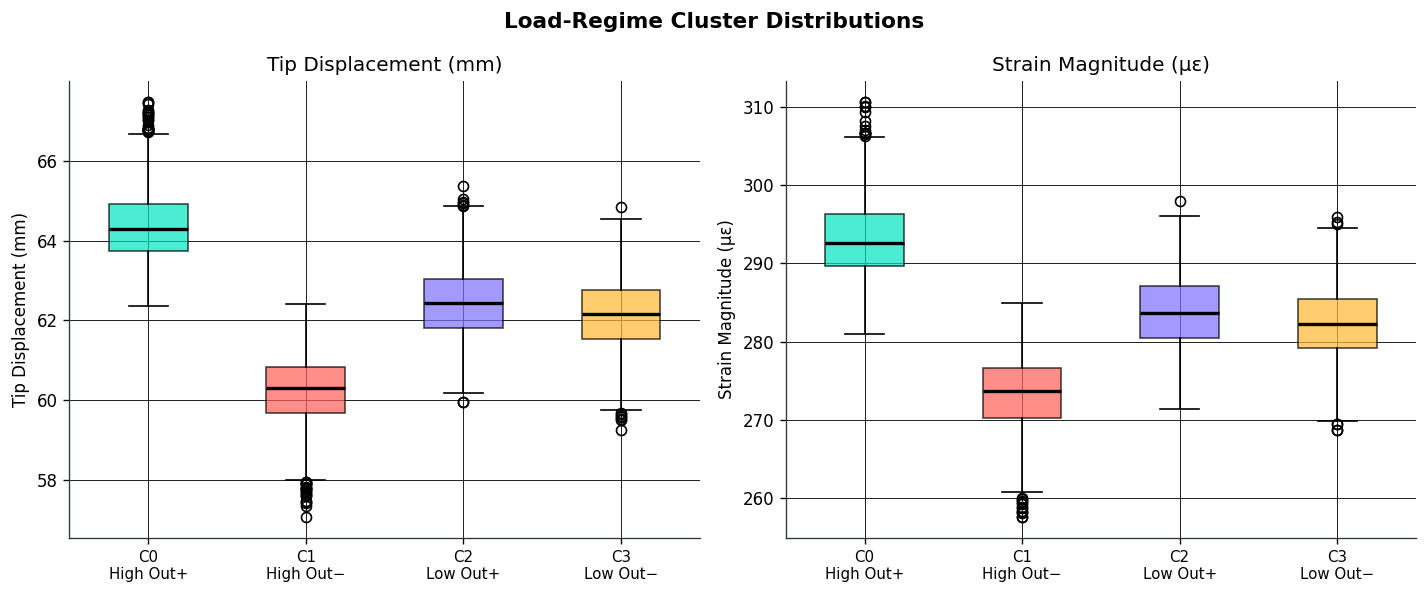

In [27]:
# ── Cluster box plots for tip displacement ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Load-Regime Cluster Distributions', fontsize=13, 
             fontweight='bold', color='black')

for ax, col, ylabel in zip(axes,
                            ['tipDisplacement', 'strain_magnitude'],
                            ['Tip Displacement (mm)', 'Strain Magnitude (με)']):
    data  = [df_eng.loc[labels4 == c, col].values for c in range(4)]
    bp    = ax.boxplot(data, patch_artist=True, widths=0.5,
                       medianprops=dict(color='black', linewidth=2))
    for patch, color in zip(bp['boxes'], PALETTE[:4]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_xticklabels([f'C{c}\n{LR_NAMES[c]}' for c in range(4)], fontsize=9,
                       color='black')
    ax.set_ylabel(ylabel, color='black')
    ax.set_title(ylabel, color='black')
    ax.set_facecolor('white')
    ax.tick_params(colors='black')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

In [28]:
# ── DBSCAN on PCA-2D ─────────────────────────────────────────
db      = DBSCAN(eps=0.5, min_samples=20)
db_lbl  = db.fit_predict(X_pca2)

n_clusters_db = len(set(db_lbl)) - (1 if -1 in db_lbl else 0)
n_noise       = int((db_lbl == -1).sum())
n_total       = len(db_lbl)

print(f"DBSCAN results:")
print(f"  Clusters found : {n_clusters_db}")
print(f"  Noise points   : {n_noise:,} ({n_noise/n_total*100:.2f}%)")
print(f"  Core points    : {n_total - n_noise:,} ({(n_total-n_noise)/n_total*100:.2f}%)")
print()
print("Interpretation: 1 cluster + 0.34% noise confirms the dataset is a")
print("continuous parametric sweep — no natural density gaps or outlier regimes.")


DBSCAN results:
  Clusters found : 1
  Noise points   : 34 (0.34%)
  Core points    : 9,967 (99.66%)

Interpretation: 1 cluster + 0.34% noise confirms the dataset is a
continuous parametric sweep — no natural density gaps or outlier regimes.


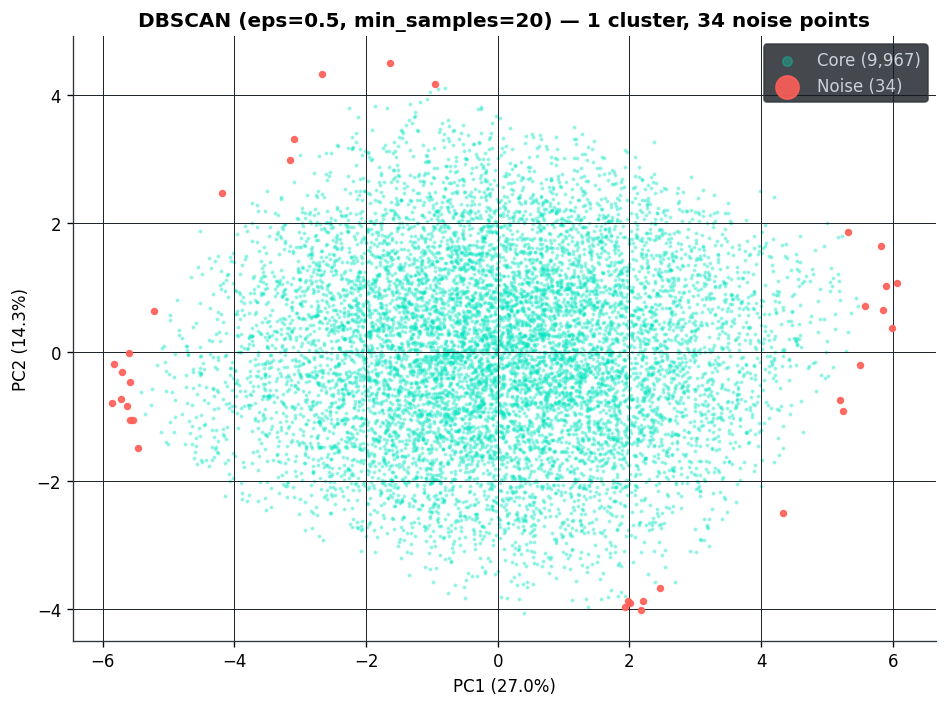

In [29]:
# ── DBSCAN visualisation ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
core_mask  = db_lbl != -1
noise_mask = db_lbl == -1

ax.scatter(X_pca2[core_mask,  0], X_pca2[core_mask,  1],
           color=PALETTE[0], s=2, alpha=0.3, label=f'Core ({core_mask.sum():,})', rasterized=True)
ax.scatter(X_pca2[noise_mask, 0], X_pca2[noise_mask, 1],
           color=PALETTE[1], s=12, alpha=0.9, label=f'Noise ({noise_mask.sum()})', zorder=5)

ax.set_xlabel(f'PC1 ({var2[0]:.1f}%)', color='black')
ax.set_ylabel(f'PC2 ({var2[1]:.1f}%)', color='black')
ax.set_title(f'DBSCAN (eps=0.5, min_samples=20) — {n_clusters_db} cluster, {n_noise} noise points',
             fontweight='bold', color='black')
ax.legend(markerscale=4, fontsize=10)
ax.set_facecolor('white')
ax.tick_params(colors='black')
fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

In [30]:
# ── Agglomerative k=2 (best silhouette match) ─────────────────
agg     = AgglomerativeClustering(n_clusters=2, linkage='ward')
agg_lbl = agg.fit_predict(X_pca10)
sil_agg = silhouette_score(X_pca10, agg_lbl, sample_size=3000, random_state=42)

print(f"Agglomerative (k=2, Ward linkage):")
print(f"  Silhouette score : {sil_agg:.4f}")
print(f"  Cluster sizes    : {dict(zip(*np.unique(agg_lbl, return_counts=True)))}")


Agglomerative (k=2, Ward linkage):
  Silhouette score : 0.0943
  Cluster sizes    : {np.int64(0): np.int64(6152), np.int64(1): np.int64(3849)}


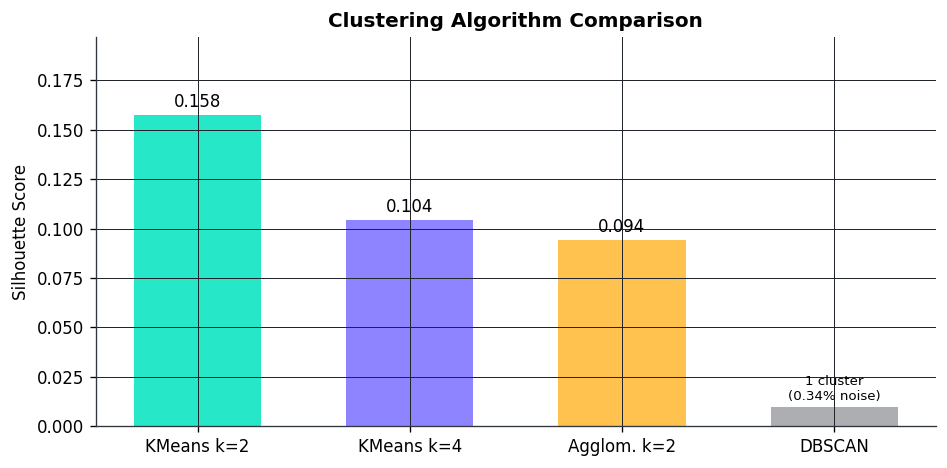

In [31]:
# ── Algorithm comparison bar chart ───────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))

algos  = ['KMeans k=2', 'KMeans k=4', 'Agglom. k=2', 'DBSCAN']
scores = [sil_scores[2], sil_scores[4], sil_agg, None]
colors_alg = [PALETTE[0], PALETTE[2], PALETTE[3], '#30363d']

for i, (algo, score, color) in enumerate(zip(algos, scores, colors_alg)):
    if score is not None:
        ax.bar(i, score, color=color, alpha=0.85, edgecolor='none', width=0.6)
        ax.text(i, score + 0.002, f'{score:.3f}', ha='center', va='bottom', 
                fontsize=10, color='black')
    else:
        ax.bar(i, 0.01, color=color, alpha=0.4, edgecolor='none', width=0.6)
        ax.text(i, 0.012, '1 cluster\n(0.34% noise)', 
                ha='center', va='bottom', fontsize=8, color='black')

ax.set_xticks(range(4)); ax.set_xticklabels(algos, color='black')
ax.set_ylabel('Silhouette Score', color='black')
ax.set_title('Clustering Algorithm Comparison', fontweight='bold', color='black')
ax.tick_params(colors='black')
ax.set_ylim(0, max(filter(None, scores)) * 1.25)
ax.set_facecolor('white')
fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

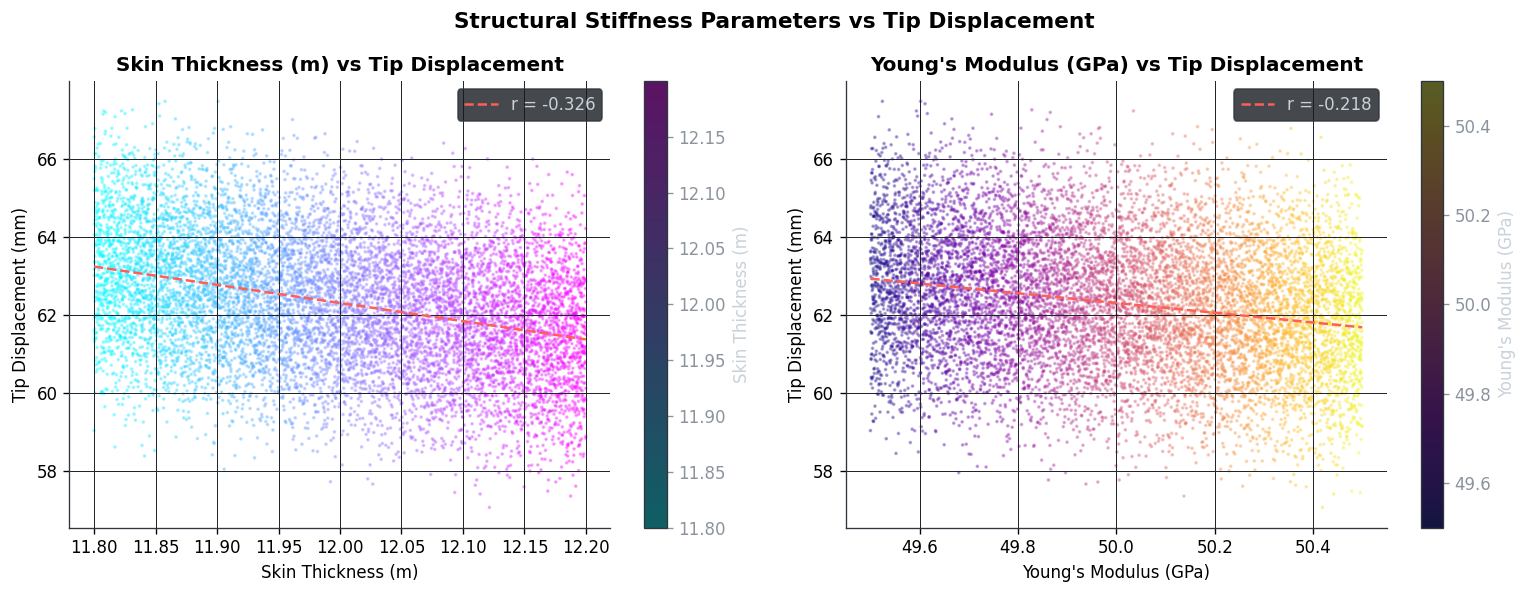

In [32]:
## ── Skin thickness vs tip displacement ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Structural Stiffness Parameters vs Tip Displacement', fontsize=13, 
             fontweight='bold', color='black')

for ax, xcol, xlabel, cmap in zip(
    axes,
    ['skinThickness', 'youngsModulus'],
    ['Skin Thickness (m)', "Young's Modulus (GPa)"],
    ['cool', 'plasma']
):
    xvals = df[xcol] if xcol == 'skinThickness' else df[xcol] / 1e9
    sc = ax.scatter(xvals, df['tipDisplacement'],
                    c=xvals, cmap=cmap, s=1.5, alpha=0.3, rasterized=True)
    plt.colorbar(sc, ax=ax, label=xlabel)

    # Linear regression
    x_arr = np.array(xvals)
    y_arr = df['tipDisplacement'].values
    slope = np.polyfit(x_arr, y_arr, 1)
    xline = np.linspace(x_arr.min(), x_arr.max(), 100)
    ax.plot(xline, np.polyval(slope, xline), color=PALETTE[1], lw=1.5,
            linestyle='--', label=f'r = {np.corrcoef(x_arr, y_arr)[0,1]:.3f}')

    ax.set_xlabel(xlabel, color='black')
    ax.set_ylabel('Tip Displacement (mm)', color='black')
    ax.set_title(f'{xlabel} vs Tip Displacement', fontweight='bold', color='black')
    ax.legend(fontsize=10)
    ax.set_facecolor('white')
    ax.tick_params(colors='black')

fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()

In [33]:
# ── Summary table ─────────────────────────────────────────────
summary = pd.DataFrame({
    'Method':    ['PCA', 'PCA', 'KMeans', 'KMeans', 'DBSCAN', 'Agglomerative'],
    'Detail':    ['Components for 95% var', 'PC1 top driver', 'Best k (silhouette)',
                  'Best silhouette score', 'Clusters found', 'Silhouette (k=2)'],
    'Result':    [f'{n_95} components',
                  'tipDisplacement (0.51)',
                  str(best_k),
                  str(sil_scores[best_k]),
                  f'{n_clusters_db} cluster ({n_noise} noise pts)',
                  str(round(sil_agg, 4))],
    'Interpretation': [
        'High intrinsic dimensionality — design space well-explored',
        'Load drives the dominant structural response axis',
        'Data best separates on outboard load sign',
        'Low silhouette expected for continuous parametric sweep',
        'Confirms continuous, dense design space — no outlier regimes',
        'Consistent with KMeans k=2 split',
    ]
})
summary


,Method,Detail,Result,Interpretation
0,PCA,Components for 95% var,10 components,High intrinsic dimensionality — design space w...
1,PCA,PC1 top driver,tipDisplacement (0.51),Load drives the dominant structural response axis
2,KMeans,Best k (silhouette),2,Data best separates on outboard load sign
3,KMeans,Best silhouette score,0.1575,Low silhouette expected for continuous paramet...
4,DBSCAN,Clusters found,1 cluster (34 noise pts),"Confirms continuous, dense design space — no o..."
5,Agglomerative,Silhouette (k=2),0.0943,Consistent with KMeans k=2 split
